# Reasoning at Inference Time: Sampling, Verifiers and Evaluation

---

> **Post-training series, part 2 of 3:** [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) → **Reasoning at Inference Time** → [RLVR and GRPO](./10_rlvr_grpo.ipynb). The three notebooks share one running analogy, a restaurant kitchen; each one opens a different station. [About the series](./00-post-training.md).

Creator: Chung-En Johnny Yu

Content updated: 2026-11-11

Hands-on practice this notebook on your Google Colab:
1. [Click here to open this notebook](https://colab.research.google.com/github/chungenyu6/ai-learning-notebooks/blob/main/02-LLM/live/09_inference_time_scaling_and_evaluation.ipynb)
2. Now, run the code and practice it!

Extends [Pretraining](../04_pretraining.ipynb) (decoding) and [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb). A model's answer quality is not fixed once training ends: *how* we sample, how much we let it "think" before answering, and how many attempts we compare all change accuracy. Spending compute at answer time instead of training time is called **inference-time scaling**. This notebook builds its pieces on a real 0.6B model: temperature and top-p, chain-of-thought, a math **verifier**, best-of-N and self-consistency, and then the harder question of how to evaluate a model when there is no verifier. [RLVR and GRPO](./10_rlvr_grpo.ipynb) reuses exactly these pieces (sample a group of answers, score them with a verifier) to *train* a model.

**Sources** — sections taken from Raschka are tagged; everything else is written for this notebook:

| Tag | Source |
|---|---|
| 📗 **[Reasoning Ch3]** | Sebastian Raschka, *Build a Reasoning Model (From Scratch)*, [Chapter 3: Evaluating Reasoning Models](https://github.com/rasbt/reasoning-from-scratch/blob/main/ch03/01_main-chapter-code/ch03_main.ipynb) — the math verifier |
| 📗 **[Reasoning Ch4]** | Raschka, [Chapter 4: Inference-Time Scaling](https://github.com/rasbt/reasoning-from-scratch/blob/main/ch04/01_main-chapter-code/ch04_main.ipynb) — temperature, top-p, chain-of-thought, self-consistency, and his published MATH-500 results table |
| 📗 **[Reasoning App. F]** | Raschka, [Appendix F: Common Approaches to LLM Evaluation](https://github.com/rasbt/reasoning-from-scratch/blob/main/chF/01_main-chapter-code/chF_main.ipynb) — multiple-choice checks, Elo ratings, the LLM-judge rubric |

The model is Raschka's Qwen3-0.6B base checkpoint (`rasbt/qwen3-from-scratch` on Hugging Face), loaded with his `reasoning_from_scratch` package. Other references, cited where used: top-p (Holtzman et al., 2019), chain-of-thought (Wei et al., 2022), self-consistency (Wang et al., 2022), MMLU (Hendrycks et al., 2020), Chatbot Arena (Chiang et al., 2024), LLM-as-a-judge (Zheng et al., 2023).

> **How this notebook works.** Nothing is trained here. We download one small published checkpoint (Qwen3-0.6B, about 1.4 GB) and use it only for short generations; results that need hundreds of generations, such as full MATH-500 accuracy, come from Raschka's published table, and the scaling curves come from a fast simulation. Every cell still runs on a laptop or Colab CPU: about 1 minute to download and load the model and about 5 minutes of generation on a laptop (longer on Colab's free CPU).

| Part | Content |
|---|---|
| 1 | Decoding: greedy, temperature, top-p, on a real next-token distribution |
| 2 | Letting the model think: chain-of-thought on a math problem |
| 3 | Verifiers: grading a math answer automatically |
| 4 | Inference-time scaling: best-of-N and self-consistency |
| 5 | Evaluating without a verifier: multiple choice, leaderboards, LLM judges |
| 6 | Interview-style check questions |

---

In [1]:
import collections, math, subprocess, sys, time
try:
    import reasoning_from_scratch  # noqa: F401
except ImportError:
    # --no-deps: the package pins an older torch; it only needs tokenizers and sympy, which Colab already has
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "reasoning-from-scratch"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tokenizers", "sympy"])

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import patches

import plotly.graph_objects as go
import plotly.io as pio
if "google.colab" not in sys.modules:          # Colab picks its own renderer
    pio.renderers.default = "plotly_mimetype+notebook_connected"

INK, ACCENT, SOFT, BLUE, GREEN, GOLD = "#2b2d42", "#ef8354", "#bfc0c0", "#4f5d75", "#7fb069", "#d7b377"
device = torch.device("cpu")      # everything here is small enough for a CPU
print("torch", torch.__version__)

torch 2.13.0


## The running analogy: a restaurant kitchen

The post-training series uses one picture: **a restaurant kitchen training an apprentice chef**. [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) covered the critic and the vote cards; this notebook is the **pass**, the counter where plates are checked before they go out. The rows for this notebook are in bold.

| In the kitchen | In post-training | Covered in |
|---|---|---|
| a food critic who learned the customers' taste from vote cards | reward model | Preference Tuning |
| cooking to please the critic, with a coach holding you back | RLHF with a KL penalty | Preference Tuning |
| **how adventurous the cook is when improvising** | **sampling temperature** | **Reasoning at Inference Time** |
| **improvising only among the few ideas that cover most of what you would normally do** | **top-p (nucleus) sampling** | **Reasoning at Inference Time** |
| **writing out the recipe steps before plating** | **chain-of-thought** | **Reasoning at Inference Time** |
| **a thermometer and a recipe checklist at the pass** | **a verifier** | **Reasoning at Inference Time**, RLVR and GRPO |
| **cooking several versions and serving the one that passes the check** | **best-of-N with a verifier** | **Reasoning at Inference Time** |
| **several cooks make the dish; serve what most of them made** | **self-consistency (majority vote)** | **Reasoning at Inference Time** |
| **customers vote between two restaurants; a ranking emerges** | **leaderboards (Elo / Bradley–Terry)** | **Reasoning at Inference Time** |
| **a restaurant inspector with a scoring sheet, and personal quirks** | **LLM-as-a-judge** | **Reasoning at Inference Time** |
| cooking eight versions and learning from how each compares with the batch average | GRPO | RLVR and GRPO |

**Where the analogy breaks.** A cook improvises a whole dish at once; a language model makes one small random choice per token, so randomness compounds over a long answer. And extra plates are not free: every extra sample costs a full generation, so inference-time scaling multiplies the serving bill.

## 1. Decoding: greedy, temperature, top-p

📗 *[Reasoning Ch3–4] model loading and code*

We load Raschka's Qwen3-0.6B **base** model, the pretrained model without any instruction or reasoning training. The first run downloads about 1.4 GB.

In [2]:
from reasoning_from_scratch.ch03 import load_model_and_tokenizer

t0 = time.time()
model, tokenizer = load_model_and_tokenizer(which_model="base", device=device, use_compile=False)
print(f"loaded in {time.time() - t0:.0f} s | parameters: {sum(p.numel() for p in model.parameters()) / 1e9:.2f} B")
# 0.75 B rather than 0.6 B: this implementation stores the output layer separately, the official count shares it with the token embedding

✓ qwen3/qwen3-0.6B-base.pth already up-to-date


loaded in 5 s | parameters: 0.75 B


At every step the model outputs one score (logit) per vocabulary entry, 151,936 of them. **Greedy decoding** takes the largest. Here is the real distribution after the prompt *"The capital of Germany is"*:

logits shape: (1, 151936) | greedy next token: ' Berlin'


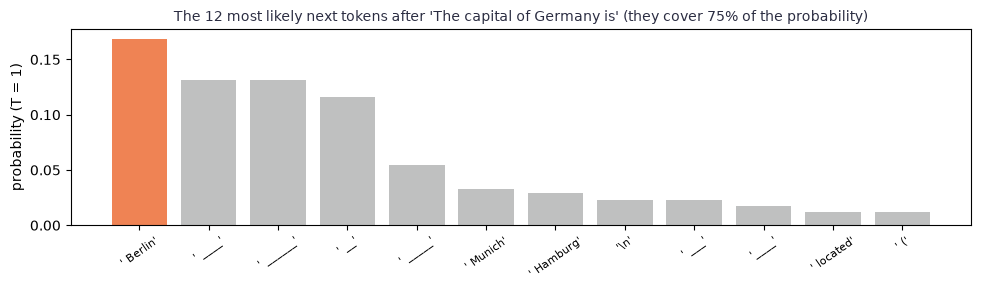

In [3]:
# Source: Raschka, reasoning-from-scratch Ch4 §4.4.1 (prompt and logits)
ex_prompt = "The capital of Germany is"
input_token_ids = torch.tensor(tokenizer.encode(ex_prompt), device=device).unsqueeze(0)
with torch.inference_mode():
    next_token_logits = model(input_token_ids)[:, -1].float()
print("logits shape:", tuple(next_token_logits.shape), "| greedy next token:", repr(tokenizer.decode([int(next_token_logits.argmax())])))

top_logits, top_ids = torch.topk(next_token_logits[0], 12)
labels = [repr(tokenizer.decode([int(i)])) for i in top_ids]
probs = torch.softmax(next_token_logits[0], -1)[top_ids]
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(12), probs, color=[ACCENT] + [SOFT] * 11)
ax.set_xticks(range(12), labels, rotation=35, fontsize=8)
ax.set_ylabel("probability (T = 1)")
ax.set_title(f"The 12 most likely next tokens after '{ex_prompt}' (they cover {probs.sum():.0%} of the probability)", color=INK, fontsize=10)
plt.tight_layout(); plt.show()

A base model has seen many web pages, quizzes and fill-in-the-blank exercises, so after "The capital of Germany is" it also considers blanks like `___` as continuations. That matters for the next step.

> [!IMPORTANT]
> **Key equation: temperature, $p_i \propto \exp(z_i/T)$.** Temperature divides the logits before the softmax. $T<1$ sharpens the distribution toward the greedy choice, $T>1$ flattens it, and $T\to0$ is greedy decoding.

Drag $T$ below; the bars are the same 12 tokens.

*Try it elsewhere:* [Transformer Explainer](https://poloclub.github.io/transformer-explainer/) runs GPT-2 in the browser and has a temperature slider on its output probabilities.

In [4]:
# Interactive: drag the temperature T. Same logits, rescaled; probabilities over the full vocabulary.
temps = [0.1, 0.2, 0.35, 0.5, 0.7, 1.0, 1.3, 1.7, 2.2, 3.0, 5.0]
default = temps.index(1.0)
fig = go.Figure(); titles = []
for T in temps:
    p_full = torch.softmax(next_token_logits[0] / T, -1)
    fig.add_bar(x=labels, y=p_full[top_ids].tolist(), marker_color=ACCENT, visible=(T == temps[default]))
    entropy = -(p_full * p_full.clamp_min(1e-30).log()).sum().item()
    titles.append(f"T = {T}: P(' Berlin') = {p_full[top_ids[0]]:.2f}, the 12 tokens hold {p_full[top_ids].sum():.0%}, "
                  f"entropy {entropy:.1f} nats")
steps = [dict(method="update", label=str(T), args=[{"visible": [j == i for j in range(len(temps))]}, {"title.text": titles[i]}])
         for i, T in enumerate(temps)]
fig.update_layout(height=400, title=titles[default], yaxis=dict(range=[0, 1], title="probability"), showlegend=False,
                  sliders=[dict(active=default, steps=steps, pad={"t": 60}, currentvalue={"prefix": "T = "})])
fig.show()

At $T=5$ the top 12 tokens hold almost nothing: the probability is spread over 150k tokens, and sampling produces near-random tokens. **Top-p** (nucleus) sampling (Holtzman et al., 2019) fixes that by keeping only the smallest set of tokens whose probability adds up to $p$, then renormalizing.

📗 *[Reasoning Ch4] §4.5 code.* Raschka's filter, checked on his toy example:

top-p = 0.8 keeps 3 of 10 tokens and renormalizes them, as in Raschka's example ✓


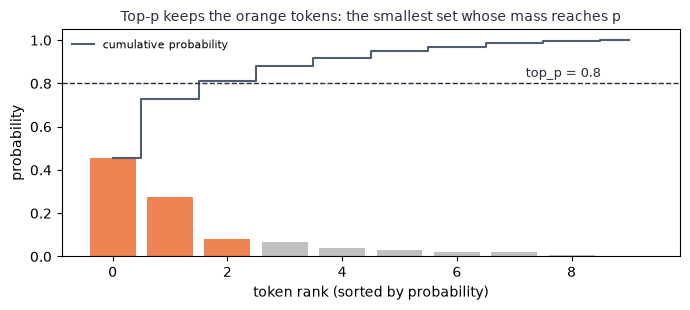

In [5]:
# Source: Raschka, reasoning-from-scratch Ch4 §4.5.2 (top_p_filter)
def top_p_filter(probas, top_p):
    if top_p is None or top_p >= 1.0:
        return probas

    # Step 4.1: Sort by descending probability
    sorted_probas, sorted_idx = torch.sort(probas, dim=1, descending=True)

    # Step 4.2: Cumulative sum
    cumprobas = torch.cumsum(sorted_probas, dim=1)

    # Step 4.3.1: Keep tokens where prefix cumulative mass (before token) is < top_p
    # Example: [0.5, 0.41, 0.09] with top_p=0.9 should keep the first two tokens
    prefix = cumprobas - sorted_probas   # cumulative mass before each token
    keep = prefix < top_p
    # Always keep at least one token (fallback for very small/non-positive top_p)
    keep[:, 0] = True

    # Step 4.3.2: Zero out beyond cutoff
    kept_sorted = torch.where(
        keep, sorted_probas,
        torch.zeros_like(sorted_probas)
    )
    # Step 4.3.3: Map back to original order
    filtered = torch.zeros_like(probas).scatter(1, sorted_idx, kept_sorted)

    # Step 4.4: Renormalize to sum to 1
    denom = torch.sum(filtered, dim=1, keepdim=True).clamp_min(1e-12)
    return filtered / denom

toy_logits = torch.tensor([[-0.7, -3.0, 0.1, -1.2, 2.0, -1.0, -0.5, -2.0, 0.3, 1.5]])
toy_probas = torch.softmax(toy_logits, dim=-1)
filtered = top_p_filter(toy_probas, top_p=0.8)
assert torch.allclose(filtered[0, [4, 8, 9]], torch.tensor([0.5589, 0.1021, 0.3390]), atol=1e-4)
assert torch.isclose(filtered.sum(), torch.tensor(1.0)) and (filtered > 0).sum() == 3
print("top-p = 0.8 keeps 3 of 10 tokens and renormalizes them, as in Raschka's example ✓")

sp, si = torch.sort(toy_probas[0], descending=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
kept = (torch.cumsum(sp, 0) - sp) < 0.8
ax.bar(range(10), sp, color=[ACCENT if k else SOFT for k in kept])
ax.step(range(10), torch.cumsum(sp, 0), where="mid", color=BLUE, label="cumulative probability")
ax.axhline(0.8, color=INK, ls="--", lw=1); ax.text(7.2, 0.83, "top_p = 0.8", color=INK, fontsize=9)
ax.set_xlabel("token rank (sorted by probability)"); ax.set_ylabel("probability"); ax.set_ylim(0, 1.05)
ax.set_title("Top-p keeps the orange tokens: the smallest set whose mass reaches p", color=INK, fontsize=10)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

In [6]:
# The same filter on the real distribution: temperature 0.35, then top-p 0.8
p_lowT = torch.softmax(next_token_logits / 0.35, dim=-1)
p_nucleus = top_p_filter(p_lowT, top_p=0.8)
kept_ids = torch.nonzero(p_nucleus[0]).flatten()
print(f"T = 0.35 alone: {int((p_lowT[0] > 1e-3).sum())} tokens above 0.1%; adding top-p 0.8 keeps {len(kept_ids)}:")
for i in kept_ids[torch.argsort(p_nucleus[0, kept_ids], descending=True)]:
    print(f"   {tokenizer.decode([int(i)])!r:12s} {p_lowT[0, i]:.3f} -> {p_nucleus[0, i]:.3f}")

T = 0.35 alone: 9 tokens above 0.1%; adding top-p 0.8 keeps 3:
   ' Berlin'    0.419 -> 0.505
   ' ____'      0.205 -> 0.247
   ' ______'    0.205 -> 0.247


> [!TIP]
> **Key idea: sampling cannot fix what the model believes.** Even at a low temperature, the base model keeps the quiz-style blanks next to *Berlin*. Decoding only chooses *how* to read the distribution.

**In the kitchen.** Temperature is how adventurous the cook feels; top-p says "improvise, but only among the dishes that make up most of what you would normally cook".

<details><summary><b>Quick check:</b> with temperature $T \to 0$, what does sampling become? And what does top-p with $p \to 0$ become?</summary>

Both become **greedy decoding**. $T\to0$ puts all probability on the largest logit; top-p with a tiny $p$ keeps only the single most likely token (Raschka's filter always keeps at least one).
</details>

## 2. Letting the model think: chain-of-thought

📗 *[Reasoning Ch3–4] prompt template and examples*

Raschka's math prompt asks for the final answer in a `\boxed{}`. A problem from the MATH-500 benchmark (correct answer: **83**):

In [7]:
# Source: Raschka, reasoning-from-scratch Ch4 §4.2–4.3 (problem, render_prompt, generation helper)
from reasoning_from_scratch.ch03 import render_prompt
from reasoning_from_scratch.ch04 import generate_text_stream_concat_flex

raw_prompt = "Half the value of $3x-9$ is $x+37$. What is the value of $x$?"
prompt = render_prompt(raw_prompt)
print(prompt)

t0 = time.time()
greedy_answer = generate_text_stream_concat_flex(model, tokenizer, prompt, device, max_new_tokens=64)
print("greedy answer:", greedy_answer.strip(), f"  ({time.time() - t0:.1f} s)")

You are a helpful math assistant.
Answer the question and write the final result on a new line as:
\boxed{ANSWER}

Question:
Half the value of $3x-9$ is $x+37$. What is the value of $x$?

Answer:


greedy answer: \boxed{20}   (0.8 s)


The base model answers immediately, and wrongly. Now add one sentence to the prompt, *"Explain step by step."* (Wei et al., 2022 call this chain-of-thought prompting):

In [8]:
prompt_cot = prompt + " \n\nExplain step by step."
t0 = time.time()
cot_answer = generate_text_stream_concat_flex(model, tokenizer, prompt_cot, device, max_new_tokens=400)
n_tokens = len(tokenizer.encode(cot_answer))
print(cot_answer.strip())
print(f"\n[{n_tokens} tokens in {time.time() - t0:.1f} s on CPU]")

To solve the problem, we need to find the value of \( x \) such that half the value of \( 3x - 9 \) is equal to \( x + 37 \).

### Step 1: Set up the equation
We are given that half the value of \( 3x - 9 \) is equal to \( x + 37 \). This can be written as:
\[
\frac{1}{2}(3x - 9) = x + 37
\]

### Step 2: Eliminate the fraction
To eliminate the fraction, multiply both sides of the equation by 2:
\[
2 \cdot \frac{1}{2}(3x - 9) = 2(x + 37)
\]
Simplifying both sides:
\[
3x - 9 = 2x + 74
\]

### Step 3: Solve for \( x \)
Subtract \( 2x \) from both sides to isolate \( x \):
\[
3x - 2x - 9 = 74
\]
Simplify:
\[
x - 9 = 74
\]
Add 9 to both sides to solve for \( x \):
\[
x = 74 + 9
\]
\[
x = 83
\]

### Final Answer:
\[
\boxed{83}
\]

[300 tokens in 12.0 s on CPU]


> [!IMPORTANT]
> **Key idea: chain-of-thought buys accuracy with tokens.** Same model, same weights, correct answer. The difference is **compute per answer**: about 5 tokens before the box versus a few hundred. Each written step becomes context for the next one, so the model can carry intermediate results instead of jumping to the answer in one token.

Raschka measured this on all 500 MATH-500 problems (his Ch3–4 table; the reasoning model is Qwen3-0.6B after reasoning training, with token counts from his Ch6 README):

| Model and prompt | MATH-500 accuracy | Average tokens per answer |
|---|---|---|
| base, greedy, plain prompt | 15.2% | 79 |
| base, greedy, "Explain step by step." | 40.6% | — |
| reasoning model, greedy | 48.2% | 1,370 |

A **reasoning model** is one trained to produce long chains of thought by itself ([RLVR and GRPO](./10_rlvr_grpo.ipynb) shows how): it buys accuracy with tokens.

**In the kitchen.** Writing the recipe steps down before plating: slower, but far fewer burnt dishes.

## 3. Verifiers: grading a math answer automatically

To compare decoding strategies on 500 problems, or to train with rewards ([RLVR and GRPO](./10_rlvr_grpo.ipynb)), we need to **grade answers automatically**. For math with a known answer, a verifier does four things:

1. **extract** the final answer (the last `\boxed{...}`, else the last number);
2. **normalize** formatting (`\dfrac{14}{3}` → `(14)/(3)`, strip `$`, degrees, `\left`, ...);
3. **compare** symbolically with SymPy, so `0.5` equals `1/2` and `28/6` equals `14/3`;
4. handle **tuples** part by part, in order.

📗 *[Reasoning Ch3] §3.4 code.* The extraction step, written out:

In [9]:
# Source: Raschka, reasoning-from-scratch Ch3 §3.4 (get_last_boxed)
def get_last_boxed(text):
    # Find the last occurrence of "\boxed"
    boxed_start_idx = text.rfind(r"\boxed")
    if boxed_start_idx == -1:
        return None

    # Get position after "\boxed"
    current_idx = boxed_start_idx + len(r"\boxed")

    # Skip any whitespace after "\boxed"
    while current_idx < len(text) and text[current_idx].isspace():
        current_idx += 1

    # Expect an opening brace "{"
    if current_idx >= len(text) or text[current_idx] != "{":
        return None

    # Parse the braces with nesting
    current_idx += 1
    brace_depth = 1
    content_start_idx = current_idx

    while current_idx < len(text) and brace_depth > 0:
        char = text[current_idx]
        if char == "{":
            brace_depth += 1
        elif char == "}":
            brace_depth -= 1
        current_idx += 1

    # Account for unbalanced braces
    if brace_depth != 0:
        return None

    # Extract content inside the outermost braces
    return text[content_start_idx:current_idx-1]

print(get_last_boxed(cot_answer), "| nested braces:", get_last_boxed(r"so \boxed{\dfrac{14}{3}}"))

83 | nested braces: \dfrac{14}{3}


📗 *[Reasoning Ch3] §3.5–3.7.* Normalization and symbolic comparison are about 200 lines of careful regex and SymPy; we import them from Raschka's package and run his test table as assertions:

In [10]:
# Source: Raschka, reasoning-from-scratch Ch3 §3.5–3.7 (test cases); functions from the package
from reasoning_from_scratch.ch03 import extract_final_candidate, normalize_text, grade_answer

tests = [
    ("3/4", r"\frac{3}{4}", True), ("(3)/(4)", r"3/4", True), (r"\frac{\sqrt{8}}{2}", "sqrt(2)", True),
    (r"\( \frac{1}{2} + \frac{1}{6} \)", "2/3", True), ("(1, 2)", r"(1,2)", True), ("(2, 1)", "(1, 2)", False),
    ("(1, 2, 3)", "(1, 2)", False), ("0.5", "1/2", True), ("0.3333333333", "1/3", False), ("1,234/2", "617", True),
    (r"\text{2/3}", "2/3", True), ("50%", "1/2", False), (r"2\cdot 3/4", "3/2", True), (r"90^\circ", "90", True),
    (r"\left(\frac{3}{4}\right)", "3/4", True), (r"2²", "2**2", True),
]
for pred, truth, expected in tests:
    assert grade_answer(pred, truth) == expected, (pred, truth)
print(f"all {len(tests)} of Raschka's verifier checks pass ✓")
print("greedy answer correct?", grade_answer(extract_final_candidate(greedy_answer), "83"),
      "| chain-of-thought answer correct?", grade_answer(extract_final_candidate(cot_answer), "83"))

all 16 of Raschka's verifier checks pass ✓
greedy answer correct? False | chain-of-thought answer correct? True


> [!WARNING]
> **Common mistake: treating a verifier as ground truth.** A verifier is a program, so it has blind spots.

Each line below is a real behaviour of this one:

In [11]:
cases = [
    (r"The answer is \boxed{83}. Wait, maybe \boxed{84}.", "83", "only the LAST box counts"),
    (r"x = 83, so 2x = 166", "83", "no box: falls back to the last number"),
    (r"\boxed{0.3333333333}", "1/3", "a rounded decimal is not 1/3"),
    (r"\boxed{50\%}", "1/2", "a percentage is not the fraction"),
    (r"I guessed. \boxed{83}", "83", "the reasoning is never checked"),
]
print(f"{'model output':52s} {'truth':6s} {'graded':7s} why")
for text, truth, why in cases:
    print(f"{text:52s} {truth:6s} {str(grade_answer(extract_final_candidate(text), truth)):7s} {why}")

model output                                         truth  graded  why
The answer is \boxed{83}. Wait, maybe \boxed{84}.    83     False   only the LAST box counts
x = 83, so 2x = 166                                  83     False   no box: falls back to the last number
\boxed{0.3333333333}                                 1/3    False   a rounded decimal is not 1/3
\boxed{50\%}                                         1/2    False   a percentage is not the fraction
I guessed. \boxed{83}                                83     True    the reasoning is never checked


| Task | Typical verifier | How it fails or can be gamed |
|---|---|---|
| math with a known answer | extract the box, normalize, symbolic equality | wrong reasoning with a right (or guessed) answer passes; correct answers in an unexpected format fail |
| code | run unit tests | special-casing the tests; tests too weak to catch bugs |
| multiple choice | compare the letter | 25% by guessing; letter or position bias |
| output format | regex (e.g., `<think>...</think>` present) | perfect format, wrong content |
| open-ended writing | none exists | needs human votes or a judge model (Part 5) |

**In the kitchen.** A thermometer at the pass: it reliably catches undercooked chicken, but it cannot taste, and it cannot tell whether the cook followed the recipe or got lucky.

## 4. Inference-time scaling: best-of-N and self-consistency

If one sample is right with probability $p$, drawing $N$ samples gives $N$ chances. Two ways to pick the final answer:

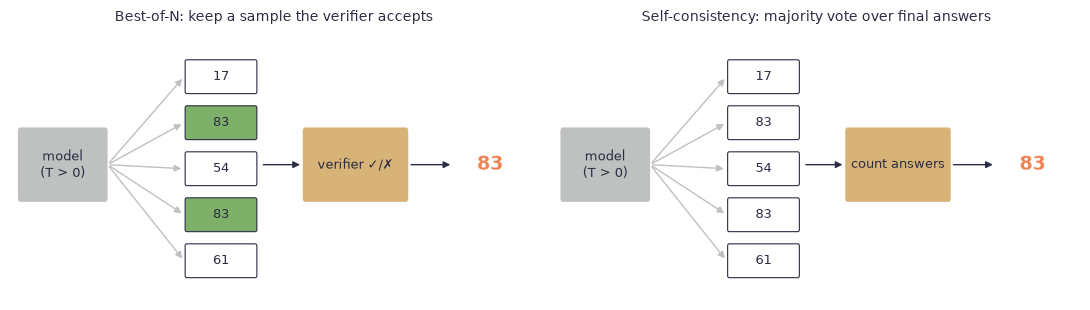

In [12]:
# Best-of-N (needs a verifier or reward model) vs self-consistency (needs only the final answers)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, title, picks, chooser in [
        (axes[0], "Best-of-N: keep a sample the verifier accepts", ["17", "83", "54", "83", "61"], "verifier ✓/✗"),
        (axes[1], "Self-consistency: majority vote over final answers", ["17", "83", "54", "83", "61"], "count answers")]:
    ax.set_xlim(0, 10); ax.set_ylim(0, 4); ax.axis("off"); ax.set_title(title, color=INK, fontsize=10)
    ax.add_patch(patches.FancyBboxPatch((0.2, 1.5), 1.6, 1, boxstyle="round,pad=0.05", fc=SOFT, ec="none"))
    ax.text(1.0, 2.0, "model\n(T > 0)", ha="center", va="center", fontsize=9, color=INK)
    for k, a in enumerate(picks):
        y = 3.3 - 0.68 * k
        ax.annotate("", xy=(3.3, y), xytext=(1.85, 2.0), arrowprops=dict(arrowstyle="-|>", color=SOFT))
        good = a == "83"
        ax.add_patch(patches.FancyBboxPatch((3.35, y - 0.22), 1.3, 0.44, boxstyle="round,pad=0.03",
                                            fc=(GREEN if good else "white") if chooser.startswith("verifier") else "white", ec=INK, lw=0.8))
        ax.text(4.0, y, a, ha="center", va="center", fontsize=9, color=INK)
    ax.add_patch(patches.FancyBboxPatch((5.6, 1.5), 1.9, 1, boxstyle="round,pad=0.05", fc=GOLD, ec="none"))
    ax.text(6.55, 2.0, chooser, ha="center", va="center", fontsize=9, color=INK)
    ax.annotate("", xy=(5.55, 2.0), xytext=(4.75, 2.0), arrowprops=dict(arrowstyle="-|>", color=INK))
    ax.annotate("", xy=(8.4, 2.0), xytext=(7.55, 2.0), arrowprops=dict(arrowstyle="-|>", color=INK))
    ax.text(9.1, 2.0, "83", ha="center", va="center", fontsize=14, weight="bold", color=ACCENT)
plt.tight_layout(); plt.show()

| | Best-of-N | Self-consistency |
|---|---|---|
| needs | a verifier or reward model that scores each sample | only a way to extract and compare final answers |
| right when | **any** sample is right and the scorer recognizes it | the right answer is the **most common** one |
| ideal accuracy | pass@N $=1-(1-p)^N$ with a perfect verifier | can stay flat or *drop* if one wrong answer is popular |
| cost | $N$ generations + $N$ scores | $N$ generations |
| also called | rejection sampling (when used to collect training data) | majority (plurality) voting |

📗 *[Reasoning Ch4] §4.6.* Raschka's `self_consistency_vote` samples answers with temperature 0.8 and top-p 0.9, extracts each final answer and votes. Five samples without and with chain-of-thought, with a budget of 1,024 new tokens per chain-of-thought answer (this cell takes about 4 minutes on a laptop CPU):

In [13]:
# Source: Raschka, reasoning-from-scratch Ch4 §4.6 (self_consistency_vote, settings)
from reasoning_from_scratch.ch04 import self_consistency_vote

t0 = time.time()
plain = self_consistency_vote(model, tokenizer, prompt, device, num_samples=5, temperature=0.8, top_p=0.9,
                              max_new_tokens=400, seed=123, show_progress=False)
cot = self_consistency_vote(model, tokenizer, prompt_cot, device, num_samples=5, temperature=0.8, top_p=0.9,
                            max_new_tokens=1024, seed=123, show_progress=False)
for name, res, cap in [("plain prompt", plain, 400), ("step by step", cot, 1024)]:
    correct = [grade_answer(a, "83") for a in res["short_answers"]]
    lengths = [len(tokenizer.encode(a)) for a in res["full_answers"]]
    print(f"{name:13s} answers {res['short_answers']}  -> vote: {res['final_answer']!r}  "
          f"| {sum(correct)}/5 correct, best-of-5 with a verifier: {any(correct)}")
    print(f"{'':13s} tokens  {lengths}  (budget {cap}; {sum(n >= cap for n in lengths)} cut off)")
print(f"({time.time() - t0:.0f} s)")

plain prompt  answers ['83', '22', '54', '83', '61']  -> vote: '83'  | 2/5 correct, best-of-5 with a verifier: True
              tokens  [252, 6, 6, 191, 6]  (budget 400; 0 cut off)
step by step  answers ['83', '-9', '83', '83', '-65']  -> vote: '83'  | 3/5 correct, best-of-5 with a verifier: True
              tokens  [423, 1024, 415, 292, 611]  (budget 1024; 1 cut off)
(234 s)


In the saved run, the plain-prompt answers scatter (2 of 5 right) and the vote still lands on 83 because the wrong answers all differ. The token counts tell why: the two right answers are the long ones (the model started reasoning on its own), the three wrong ones answered in 6 tokens. With chain-of-thought, 3 of 5 are right. Look at the token counts: one chain of thought ran out of its budget, and the verifier's fallback picked a stray number from the unfinished text. A first version of this notebook used a 400-token budget and four of five answers were cut off, which turned a mostly right model into a tie. **The token budget is part of the method**; Raschka evaluates with 2,048 tokens, and his GRPO training in [RLVR and GRPO](./10_rlvr_grpo.ipynb) caps answers at 512.

> [!IMPORTANT]
> **Key fact: best-of-N needs one right sample; voting needs the right answer to be the most common one.** With a perfect verifier, accuracy is pass@N $=1-(1-p)^N$; voting turns "sometimes right" into "usually right" only when the right answer beats every popular wrong one.

To see *when* each method helps we need thousands of problems, so we simulate a solver: on every problem, each sample is right with probability $p$; a wrong sample lands on one of 5 wrong answers, with one "popular" wrong answer (a common mistake) chosen more often. Drag $p$:

In [14]:
# Interactive: drag the single-sample accuracy p. Simulated, 20,000 problems per setting.
rng = np.random.default_rng(0)
Ns = [1, 2, 3, 5, 8, 12, 16, 24, 32]
WRONG = np.array([0.4, 0.15, 0.15, 0.15, 0.15])          # answer 1 is the "popular" mistake

def simulate(p, N, n_problems=20_000, verifier_fpr=0.0):
    right = rng.random((n_problems, N)) < p
    wrong = 1 + rng.choice(len(WRONG), size=(n_problems, N), p=WRONG)
    answers = np.where(right, 0, wrong)                    # 0 = the correct answer
    counts = np.stack([(answers == a).sum(1) for a in range(len(WRONG) + 1)], 1)
    top = counts.max(1, keepdims=True)
    tied = counts == top
    vote_right = tied[:, 0] / tied.sum(1)                  # random tie-break
    accepted = right | (rng.random((n_problems, N)) < verifier_fpr)
    first = np.argmax(accepted, 1)                         # first sample the verifier accepts (if any)
    bon = np.where(accepted.any(1), right[np.arange(n_problems), first], right[:, 0])
    return right.any(1).mean(), vote_right.mean(), bon.mean()

ps = [0.15, 0.25, 0.35, 0.45, 0.55, 0.7]
default = ps.index(0.35)
fig = go.Figure(); titles = []
for p in ps:
    res = np.array([simulate(p, N) for N in Ns])
    noisy = np.array([simulate(p, N, verifier_fpr=0.1)[2] for N in Ns])
    vis = p == ps[default]
    fig.add_scatter(x=Ns, y=res[:, 0], name="best-of-N, perfect verifier (pass@N)", line=dict(color=GREEN, width=3), visible=vis)
    fig.add_scatter(x=Ns, y=noisy, name="best-of-N, verifier accepts 10% of wrong answers", line=dict(color=GOLD, dash="dash"), visible=vis)
    fig.add_scatter(x=Ns, y=res[:, 1], name="self-consistency (majority vote)", line=dict(color=ACCENT, width=3), visible=vis)
    titles.append(f"single-sample accuracy p = {p}: at N = 32, vote {res[-1, 1]:.0%}, perfect verifier {res[-1, 0]:.0%}")
k = 3
steps = [dict(method="update", label=str(p), args=[{"visible": [j // k == i for j in range(k * len(ps))]}, {"title.text": titles[i]}])
         for i, p in enumerate(ps)]
fig.update_layout(height=430, title=titles[default], xaxis=dict(title="number of samples N", type="log", tickvals=Ns),
                  yaxis=dict(range=[0, 1.02], title="accuracy"), legend=dict(x=0.45, y=0.08),
                  sliders=[dict(active=default, steps=steps, pad={"t": 50}, currentvalue={"prefix": "p = "})])
fig.show()

What the curves say:

- **A perfect verifier** turns more samples into accuracy fastest; it only needs *one* right sample.
- **Majority vote** helps only while the right answer beats the popular wrong one. At $p = 0.15$ the popular mistake (34% of samples) is more common than the right answer (15%), so voting gets *worse* with more samples: 5% at $N = 32$, while a perfect verifier reaches 99%.
- **A leaky verifier** loses part of the gain, because each extra sample is another chance to accept a wrong answer.

The real numbers. Raschka ran these methods on all 500 MATH-500 problems with the base model (his Ch4 table, on a DGX Spark GPU):

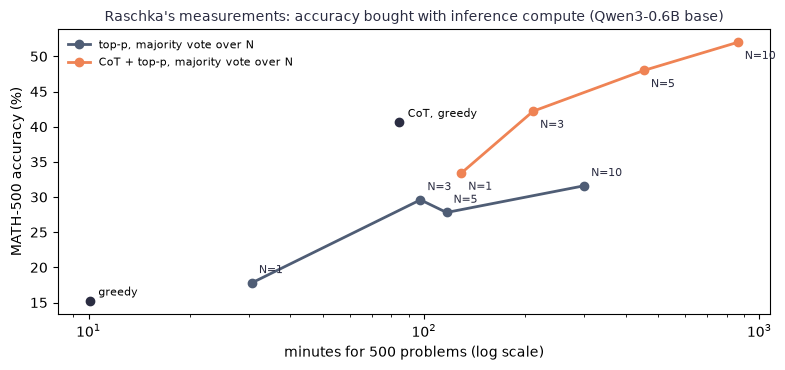

In [15]:
# Source: Raschka, reasoning-from-scratch Ch4 §4.6 (published results table, base model)
real = [  # (label, N samples, accuracy %, minutes)
    ("greedy", 1, 15.2, 10.1), ("CoT, greedy", 1, 40.6, 84.5),
    ("top-p", 1, 17.8, 30.7), ("top-p + vote", 3, 29.6, 97.6), ("top-p + vote", 5, 27.8, 116.8), ("top-p + vote", 10, 31.6, 300.4),
    ("CoT + top-p", 1, 33.4, 129.2), ("CoT + top-p + vote", 3, 42.2, 211.6), ("CoT + top-p + vote", 5, 48.0, 452.9),
    ("CoT + top-p + vote", 10, 52.0, 862.6),
]
fig, ax = plt.subplots(figsize=(8, 3.8))
for family, color in [("top-p", BLUE), ("CoT + top-p", ACCENT)]:
    pts = [r for r in real if r[0] in (family, family + " + vote")]          # N = 1, then votes over 3, 5, 10
    ax.plot([r[3] for r in pts], [r[2] for r in pts], "o-", color=color, lw=2, label=f"{family}, majority vote over N")
    for r in pts:
        ax.annotate(f"N={r[1]}", (r[3], r[2]), (5, -12 if family.startswith("CoT") else 7), textcoords="offset points", fontsize=8, color=INK)
for r in real[:2]:
    ax.scatter(r[3], r[2], color=INK, zorder=5); ax.annotate(r[0], (r[3], r[2]), (6, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("minutes for 500 problems (log scale)"); ax.set_ylabel("MATH-500 accuracy (%)")
ax.set_title("Raschka's measurements: accuracy bought with inference compute (Qwen3-0.6B base)", color=INK, fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

- Voting without chain-of-thought plateaus around 30%: the samples are too often wrong in the same way.
- Chain-of-thought plus voting keeps climbing, from 33% to 52% at $N = 10$, above the 48% of the trained reasoning model with greedy decoding (Part 2), **with no training at all**. The price: about 10× the time of a single chain-of-thought pass, and almost 5× the reasoning model's.

> [!IMPORTANT]
> **Key idea: accuracy can be bought at training time or at answer time.** That trade-off is the core of inference-time scaling: accuracy can be bought either at training time ([RLVR and GRPO](./10_rlvr_grpo.ipynb)) or at answer time, and serving cost decides which is cheaper.

**In the kitchen.** Ten cooks making the same dish and serving the most common version beats one careful cook, but you are paying ten cooks.

## 5. Evaluating without a verifier

Most tasks have no program that says "correct": summaries, advice, code style, conversation. Three common substitutes, each with its own failure mode:

| Method | What it measures | Weakness |
|---|---|---|
| multiple choice (MMLU-style) | picking one of A–D | 25% by guessing; tests recognition, not generation; sensitive to prompt format |
| pairwise human votes → leaderboard | which answer people prefer | expensive; favours style, length and confidence; votes from a particular user group |
| LLM-as-a-judge | a strong model grades with a rubric | judge biases (below); judging is only as good as the judge |

### Multiple choice

📗 *[Reasoning App. F] §F.2.* Raschka's example question, graded by the first letter the model generates:

In [16]:
# Source: Raschka, reasoning-from-scratch Appendix F §F.2 (example, prompt format, predict_choice)
from reasoning_from_scratch.appendix_f import predict_choice

example = {"question": "How many ways are there to put 4 distinguishable balls into 2 indistinguishable boxes?",
           "choices": ["7", "11", "16", "8"], "answer": "D"}

def format_prompt(example):
    return (f"{example['question']}\n"
            f"A. {example['choices'][0]}\nB. {example['choices'][1]}\nC. {example['choices'][2]}\nD. {example['choices'][3]}\n"
            "Answer: ")

mc_prompt = format_prompt(example)
prompt_fmt = torch.tensor(tokenizer.encode(mc_prompt), device=device).unsqueeze(0)
pred = predict_choice(model, tokenizer, prompt_fmt)
print(mc_prompt + f"\ngenerated letter: {pred} | correct: {example['answer']}")

How many ways are there to put 4 distinguishable balls into 2 indistinguishable boxes?
A. 7
B. 11
C. 16
D. 8
Answer: 
generated letter: C | correct: D


Evaluation harnesses often skip generation and compare the model's **probability for each letter** instead, which is cheaper and avoids parsing problems:

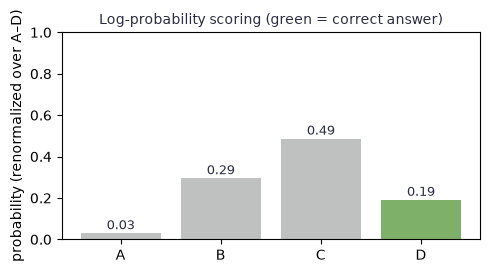

argmax letter: C


In [17]:
with torch.inference_mode():
    last = model(prompt_fmt)[0, -1].float()
letter_ids = [tokenizer.encode(l)[0] for l in "ABCD"]
letter_p = torch.softmax(last[letter_ids], -1)
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(list("ABCD"), letter_p, color=[GREEN if l == example["answer"] else SOFT for l in "ABCD"])
for i, v in enumerate(letter_p.tolist()):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("probability (renormalized over A–D)")
ax.set_title("Log-probability scoring (green = correct answer)", color=INK, fontsize=10)
plt.tight_layout(); plt.show()
print("argmax letter:", "ABCD"[int(letter_p.argmax())])

Both readings agree, and both are wrong: the model puts about half its probability on C and less than a fifth on the correct D. Log-probabilities also show *how* wrong, which a single generated letter hides. One question says nothing about overall ability; benchmarks such as MMLU (Hendrycks et al., 2020) average thousands of questions so that guessing noise (25% per question) averages out.

### Leaderboards: Elo is Bradley–Terry again

📗 *[Reasoning App. F] §F.4 code.* Arena-style leaderboards collect "answer A or answer B?" votes between models. Raschka's Elo update:

In [18]:
# Source: Raschka, reasoning-from-scratch Appendix F §F.4 (votes, elo_ratings)
from reasoning_from_scratch.appendix_f import elo_ratings

votes = [("GPT-5", "Claude-3"), ("GPT-5", "Llama-4"), ("Claude-3", "Llama-3"),
         ("Llama-4", "Llama-3"), ("Claude-3", "Llama-3"), ("GPT-5", "Llama-3")]   # (winner, loser)
ratings = elo_ratings(votes, k_factor=32, initial_rating=1000)
for m in sorted(ratings, key=ratings.get, reverse=True):
    print(f"{m:9s} {ratings[m]:7.1f}")

GPT-5      1043.7
Claude-3   1015.2
Llama-4    1000.7
Llama-3     940.4


> [!IMPORTANT]
> **Key fact: Elo is Bradley–Terry on a different scale.** The expected score in Elo is $1/(1+10^{(R_l-R_w)/400})$: a logistic function of the rating **difference**, exactly the Bradley–Terry model from [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) on a different scale. Chatbot Arena (Chiang et al., 2024) moved from online Elo updates to fitting Bradley–Terry on all votes at once, because Elo depends on the order of the votes.

A check on these six votes:

In [19]:
models = sorted(ratings)
idx = {m: i for i, m in enumerate(models)}
theta = torch.zeros(len(models), requires_grad=True)
opt = torch.optim.Adam([theta], lr=0.05)
w = torch.tensor([idx[a] for a, b in votes]); l = torch.tensor([idx[b] for a, b in votes])
for _ in range(2000):
    loss = -F.logsigmoid(theta[w] - theta[l]).mean() + 1e-2 * (theta ** 2).mean()   # Bradley–Terry + a little ridge
    opt.zero_grad(); loss.backward(); opt.step()
bt = {m: 1000 + 400 / math.log(10) * (theta[idx[m]] - theta.mean()).item() for m in models}   # Elo-like scale
reversed_elo = elo_ratings(list(reversed(votes)))
print(f"{'model':9s} {'Elo':>7s} {'Elo, votes reversed':>20s} {'Bradley–Terry':>14s}")
for m in sorted(ratings, key=ratings.get, reverse=True):
    print(f"{m:9s} {ratings[m]:7.1f} {reversed_elo[m]:20.1f} {bt[m]:14.1f}")
assert sorted(bt, key=bt.get) == sorted(ratings, key=ratings.get)
print("same ranking from Elo and Bradley–Terry ✓ (Elo values depend on vote order; Bradley–Terry does not)")

model         Elo  Elo, votes reversed  Bradley–Terry
GPT-5      1043.7               1047.8         1542.2
Claude-3   1015.2               1012.6         1038.0
Llama-4    1000.7                998.6          990.0
Llama-3     940.4                941.0          429.8
same ranking from Elo and Bradley–Terry ✓ (Elo values depend on vote order; Bradley–Terry does not)


The ranking agrees, the scales do not. Elo moves each rating by at most $K=32$ per vote, so after six votes everyone is still near 1000. Bradley–Terry fits all votes at once, and because GPT-5 never lost, its maximum-likelihood rating would be infinite; the small penalty in the loss keeps it finite. With few votes, every leaderboard number has a wide confidence interval, which is why arenas publish intervals and require thousands of votes per model.

### LLM-as-a-judge

📗 *[Reasoning App. F] §F.5.* Raschka grades answers with a larger model (gpt-oss 20B through Ollama) and a 1–5 rubric. We do not run a 20B judge here; the prompt and his saved result:

In [20]:
# Source: Raschka, reasoning-from-scratch Appendix F §F.5 (rubric prompt and the judge's saved output)
def rubric_prompt(instruction, reference_answer, model_answer):
    rubric = (
        "You are a fair judge assistant. You will be given an instruction, "
        "a reference answer, and a candidate answer to evaluate, according "
        "to the following rubric:\n\n"
        "1: The response fails to address the instruction, providing "
        "irrelevant, incorrect, or excessively verbose content.\n"
        "2: The response partially addresses the instruction but contains "
        "major errors, omissions, or irrelevant details.\n"
        "3: The response addresses the instruction to some degree but is "
        "incomplete, partially correct, or unclear in places.\n"
        "4: The response mostly adheres to the instruction, with only "
        "minor errors, omissions, or lack of clarity.\n"
        "5: The response fully adheres to the instruction, providing a "
        "clear, accurate, and relevant answer in a concise and efficient "
        "manner.\n\n"
        "Now here is the instruction, the reference answer, and the "
        "response.\n"
    )
    return (f"{rubric}\nInstruction:\n{instruction}\n\nReference Answer:\n{reference_answer}\n\n"
            f"Answer:\n{model_answer}\n\nEvaluation: ")

print(rubric_prompt("If all birds can fly, and a penguin is a bird, can a penguin fly?",
                    "Yes, according to the premise that all birds can fly, a penguin can fly.",
                    "Yes – under those premises a penguin would be able to fly."))
print("--- gpt-oss:20b's saved verdict ---\n**Score: 5**\nThe candidate answer directly addresses the question, "
      "correctly applies the given premises, and concisely states that a penguin would be able to fly. "
      "It is accurate, relevant, and clear.")

You are a fair judge assistant. You will be given an instruction, a reference answer, and a candidate answer to evaluate, according to the following rubric:

1: The response fails to address the instruction, providing irrelevant, incorrect, or excessively verbose content.
2: The response partially addresses the instruction but contains major errors, omissions, or irrelevant details.
3: The response addresses the instruction to some degree but is incomplete, partially correct, or unclear in places.
4: The response mostly adheres to the instruction, with only minor errors, omissions, or lack of clarity.
5: The response fully adheres to the instruction, providing a clear, accurate, and relevant answer in a concise and efficient manner.

Now here is the instruction, the reference answer, and the response.

Instruction:
If all birds can fly, and a penguin is a bird, can a penguin fly?

Reference Answer:
Yes, according to the premise that all birds can fly, a penguin can fly.

Answer:
Yes – 

Judges are cheap and scale to thousands of answers, but they have measurable biases (Zheng et al., 2023):

| Bias | What happens | Common mitigation |
|---|---|---|
| position | in A-vs-B comparisons the judge favours one slot | judge both orders; count only consistent verdicts |
| verbosity | longer answers get higher scores | length-controlled scores; rubrics that penalize padding |
| self-preference | a judge rates answers in its own style higher | use a different model family as judge, or several judges |
| limited ability | the judge cannot check what it cannot solve (hard math, code) | give it the reference answer, or use a verifier where one exists |

> [!WARNING]
> **Common mistake: training against a judge as if it were ground truth.** A judge model is a **reward model** ([Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb)) used for evaluation, and when it is used to *train* a policy, all of its biases become things to exploit, the reward hacking of [Preference Tuning](./08_preference_tuning_rlhf_dpo.ipynb) Part 7. A verifier, when one exists, is the cure; [RLVR and GRPO](./10_rlvr_grpo.ipynb) trains on exactly that.

**In the kitchen.** The inspector with a scoring sheet tastes far more plates than customers ever vote on, but always likes the first plate a bit more and big portions a lot more.

> [!IMPORTANT]
> **Key takeaways**
>
> 1. Decoding only chooses how to read the model's distribution: temperature $p_i\propto e^{z_i/T}$ sharpens or flattens it, top-p cuts the long tail; neither fixes what the model believes.
> 2. Chain-of-thought spends more tokens per answer and can multiply accuracy without any training.
> 3. A verifier (extract, normalize, compare) makes math and code gradable automatically, but it has blind spots and can be gamed.
> 4. Best-of-N needs one right sample and a good verifier, pass@N $=1-(1-p)^N$; self-consistency needs the right answer to be the most common; both multiply serving cost.
> 5. Without a verifier: multiple choice, human-vote leaderboards (Elo = Bradley–Terry) and LLM judges, each with its own biases; a judge used for training becomes a reward to hack.

## 6. Check yourself (interview-style)

<details><summary><b>Q1. Explain greedy decoding, temperature and top-p. When would you use which?</b></summary>

Greedy takes the most likely token each step: deterministic, good for short factual answers and for evaluation, but prone to repetition. Temperature divides logits by $T$ before softmax: $T<1$ sharpens, $T>1$ flattens. Top-p keeps the smallest set of tokens whose probability reaches $p$ and renormalizes, cutting off the long tail that high temperatures would otherwise sample. Sampling ($T\approx0.6$–$1$, top-p $\approx0.9$) is needed for creative text and for drawing *diverse* samples in self-consistency or RL.
</details>

<details><summary><b>Q2. What is inference-time (test-time) scaling? Name three ways to do it.</b></summary>

Spending more compute per query to get better answers, without changing the weights. Ways: longer reasoning (chain-of-thought prompting, or reasoning models trained to think longer); parallel sampling with selection (best-of-N with a verifier or reward model, self-consistency voting); sequential refinement (the model critiques and revises its answer). Cost grows with tokens generated, so it trades serving cost for accuracy.
</details>

<details><summary><b>Q3. Best-of-N vs self-consistency: what does each need and when does each fail?</b></summary>

Best-of-N needs a scorer (verifier or reward model) for each sample; with a perfect verifier accuracy is pass@N $=1-(1-p)^N$, but a flawed reward model gets exploited as $N$ grows (more chances to pick a hacked answer). Self-consistency needs only extractable final answers and works when the correct answer is the most common; it fails when a popular wrong answer dominates, and it does not apply to open-ended outputs without a canonical answer.
</details>

<details><summary><b>Q4. How does a math verifier work, and what are its blind spots?</b></summary>

Extract the final answer (last `\boxed{}`, else last number), normalize LaTeX and formatting, compare symbolically (SymPy) with the reference, part by part for tuples. Blind spots: it never checks the reasoning, so lucky guesses pass; correct answers in unexpected formats can fail; and the extraction rule (last box) can be gamed or tripped.
</details>

<details><summary><b>Q5. Why did chain-of-thought raise the base model from 15% to 41% on MATH-500?</b></summary>

The model spends more tokens, and each written step becomes context for the next, so intermediate results do not have to be computed in a single forward pass. The weights are unchanged; the prompt elicits a computation the model could already do. Reasoning models are trained (with RL, [RLVR and GRPO](./10_rlvr_grpo.ipynb)) to do this by default and for longer.
</details>

<details><summary><b>Q6. How would you evaluate an LLM on a task with no ground truth? What can go wrong?</b></summary>

Pairwise human preference votes aggregated with Bradley–Terry/Elo, or an LLM judge with a rubric and reference answers, validated against a sample of human labels. Risks: position, verbosity and self-preference biases; judges that cannot solve the task; leaderboards rewarding style over correctness; and once the judge is used as a training reward, the policy learns to exploit it.
</details>

<details><summary><b>Q7. Elo vs Bradley–Terry for leaderboards?</b></summary>

Both model $P(A \text{ beats } B)$ as a logistic function of a rating difference. Elo updates ratings online, one vote at a time, so the result depends on vote order and the step size $K$. Bradley–Terry fits all ratings jointly by maximum likelihood, is order-independent and gives confidence intervals by bootstrapping, which is why Chatbot Arena switched to it.
</details>

<details><summary><b>Q8. Explain inference-time scaling to a non-engineer in 30 seconds.</b></summary>

"A cook can get better results without more training: write the recipe steps down before plating, or have several cooks make the same dish and serve the version most of them made, or check each plate with a thermometer and serve one that passes. All of these cost more time per dish. Modern AI models do the same: they think longer or try several times before answering, and you pay for every extra attempt."
</details>

## References

- Raschka (2025), *Build a Reasoning Model (From Scratch)*, [rasbt/reasoning-from-scratch](https://github.com/rasbt/reasoning-from-scratch): Chapter 3 (verifier), Chapter 4 (inference-time scaling), Appendix F (evaluation); Qwen3-0.6B checkpoints on [Hugging Face](https://huggingface.co/rasbt/qwen3-from-scratch).
- Holtzman et al. (2019), *The Curious Case of Neural Text Degeneration* (top-p), [arXiv:1904.09751](https://arxiv.org/abs/1904.09751).
- Wei et al. (2022), *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models*, [arXiv:2201.11903](https://arxiv.org/abs/2201.11903).
- Wang et al. (2022), *Self-Consistency Improves Chain of Thought Reasoning in Language Models*, [arXiv:2203.11171](https://arxiv.org/abs/2203.11171).
- Hendrycks et al. (2021), *Measuring Mathematical Problem Solving With the MATH Dataset*, [arXiv:2103.03874](https://arxiv.org/abs/2103.03874); Lightman et al. (2023), *Let's Verify Step by Step* (the MATH-500 subset), [arXiv:2305.20050](https://arxiv.org/abs/2305.20050).
- Hendrycks et al. (2020), *Measuring Massive Multitask Language Understanding* (MMLU), [arXiv:2009.03300](https://arxiv.org/abs/2009.03300).
- Chiang et al. (2024), *Chatbot Arena: An Open Platform for Evaluating LLMs by Human Preference*, [arXiv:2403.04132](https://arxiv.org/abs/2403.04132).
- Zheng et al. (2023), *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*, [arXiv:2306.05685](https://arxiv.org/abs/2306.05685).
- Snell et al. (2024), *Scaling LLM Test-Time Compute Optimally can be More Effective than Scaling Model Parameters*, [arXiv:2408.03314](https://arxiv.org/abs/2408.03314).